# Practical 1: CIFAR-10 Dataset and Image Preprocessing

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
# Load CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

# Print dataset shapes
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)

# Print unique labels
print("Unique labels:", np.unique(y_train))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3048s 18us/step
X_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
X_test shape : (10000, 32, 32, 3)
y_test shape : (10000, 1)
Unique labels: [0 1 2 3 4 5 6 7 8 9]


#### Task 1: Load CIFAR-10 dataset

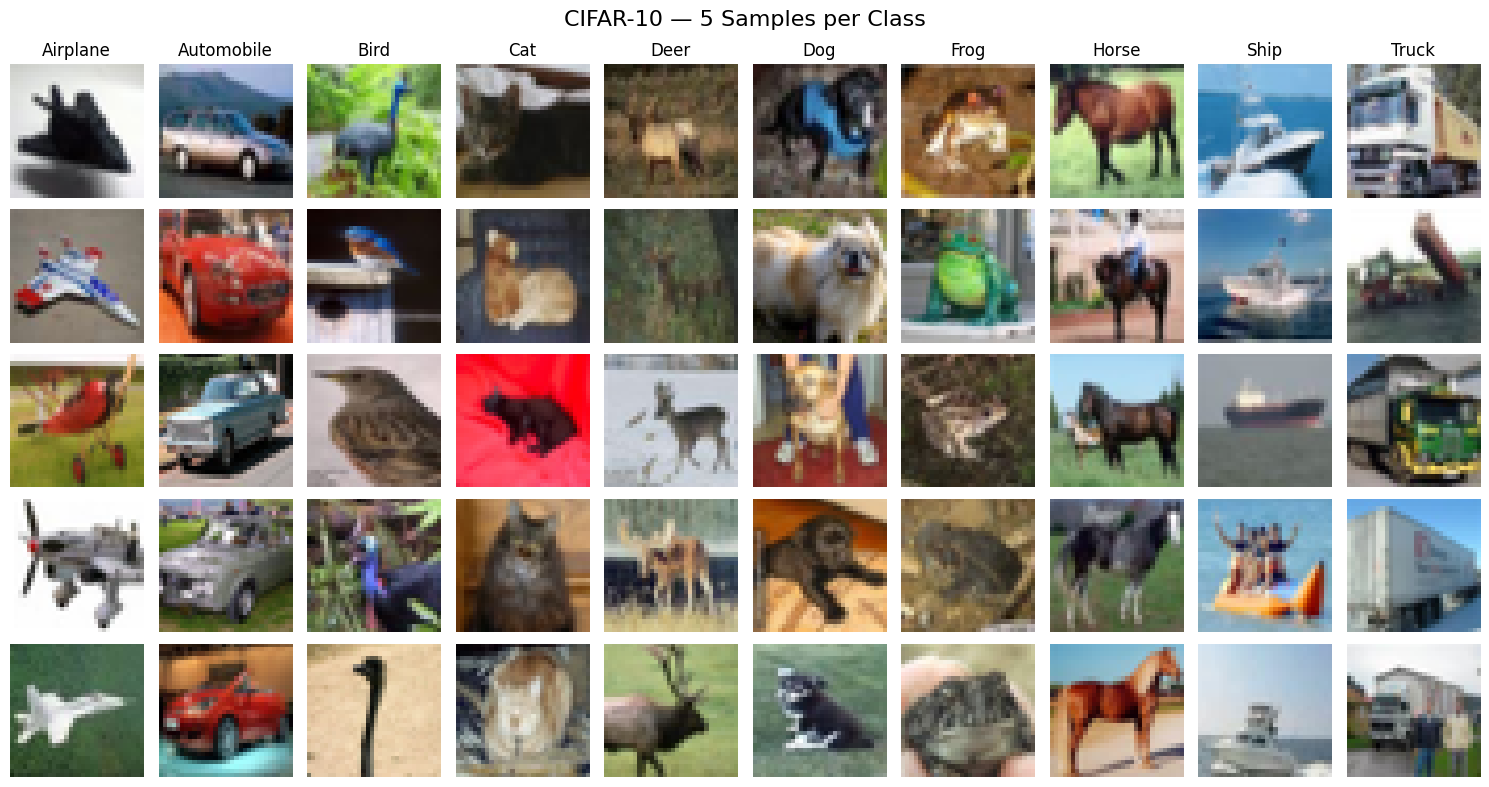

In [ ]:
# CIFAR-10 class names
class_names = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

# Create 5 x 10 grid
fig, axes = plt.subplots(5, 10, figsize=(15, 8))

for class_id in range(10):

    # Find images belonging to this class
    class_indices = np.where(y_train.flatten() == class_id)[0]

    # Select first 5 images
    selected_indices = class_indices[:5]

    for row, index in enumerate(selected_indices):
        axes[row, class_id].imshow(X_train[index])
        axes[row, class_id].axis("off")

        # Add class name at top of each column
        if row == 0:
            axes[row, class_id].set_title(class_names[class_id])

plt.suptitle("CIFAR-10 — 5 Samples per Class", fontsize=16)
plt.tight_layout()
plt.show()

#### Task 2: CIFAR-10 class names

### Observation

CIFAR-10 contains 10 different object classes. Some classes such as airplane, automobile, ship and truck have relatively clear visual differences, while classes such as cat, dog, deer and horse can have similar shapes, colours and backgrounds. These visually similar classes may be harder for the CNN to classify correctly.

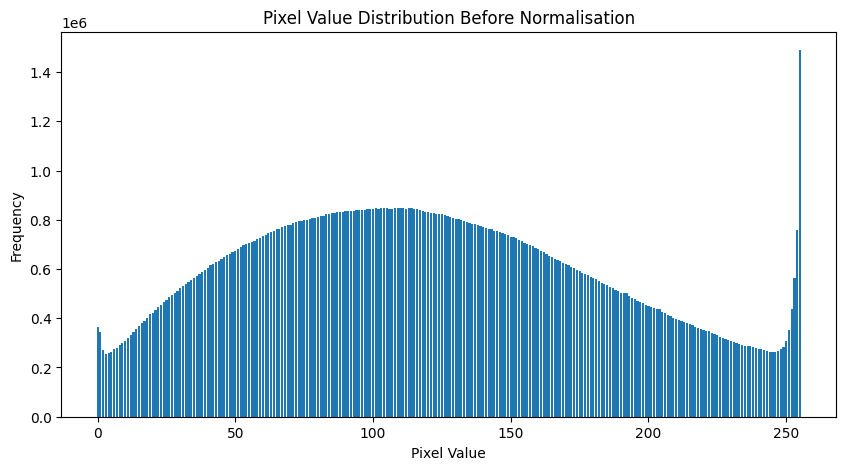

In [ ]:
# Count frequency of each pixel value
pixel_counts = np.bincount(X_train.flatten(), minlength=256)

# Plot histogram
plt.figure(figsize=(10, 5))

plt.bar(range(256), pixel_counts)

plt.title("Pixel Value Distribution Before Normalisation")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")

plt.show()

#### Task 3: Count frequency of each pixel value

In [ ]:
# Normalize pixel values from 0-255 to 0-1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


#### Task 4: Normalize pixel values from 0-255 to 0-1

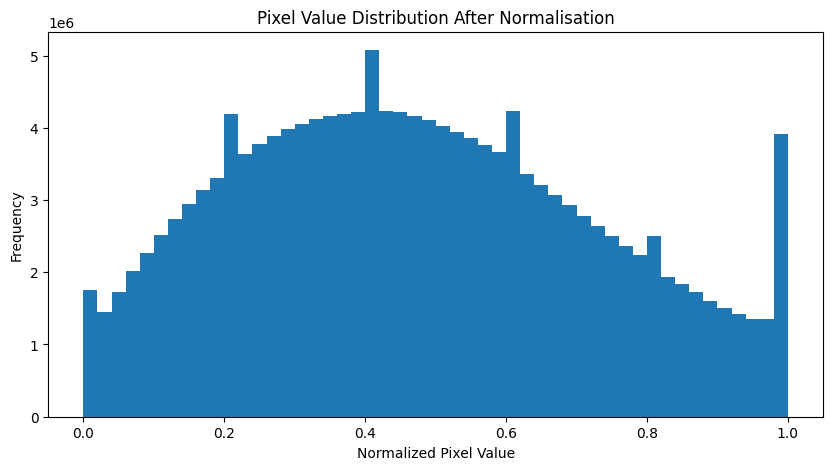

In [ ]:
# Plot normalized pixel distribution

plt.figure(figsize=(10, 5))

plt.hist(X_train.flatten(), bins=50)

plt.title("Pixel Value Distribution After Normalisation")
plt.xlabel("Normalized Pixel Value")
plt.ylabel("Frequency")

plt.show()

#### Task 5: Plot normalized pixel distribution

### Why Normalisation?

The original CIFAR-10 pixel values range from 0 to 255. We divide the pixel values by 255 so that they fall between 0 and 1.

Normalisation helps the neural network train more efficiently because the input values are on a smaller and consistent scale. Without normalisation, large raw pixel values can result in larger gradients and unstable or slower training.

In [ ]:
# One-hot encode the labels
y_train_oh = keras.utils.to_categorical(y_train, 10)
y_test_oh = keras.utils.to_categorical(y_test, 10)

# Print shapes
print("Original y_train shape :", y_train.shape)
print("One-hot y_train shape   :", y_train_oh.shape)

print("Original y_test shape  :", y_test.shape)
print("One-hot y_test shape    :", y_test_oh.shape)

Original y_train shape : (50000, 1)
One-hot y_train shape   : (50000, 10)
Original y_test shape  : (10000, 1)
One-hot y_test shape    : (10000, 10)


#### Task 6: One-hot encode the labels

In [ ]:
# Check first 5 labels

for i in range(5):
    print("Original:", y_train[i][0])
    print("One-hot :", y_train_oh[i])
    print()

Original: 6
One-hot : [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]

Original: 9
One-hot : [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]

Original: 9
One-hot : [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]

Original: 4
One-hot : [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]

Original: 1
One-hot : [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]



#### Task 7: Check first 5 labels

### Why One-Hot Encoding?

The CNN will have 10 output neurons, one for each CIFAR-10 class. The softmax activation produces a probability distribution across these 10 classes.

One-hot encoding represents the correct class as 1 and all other classes as 0. This matches the output format required by categorical cross-entropy loss.

# CNN vs ANN — Image Classification

### ANN (Artificial Neural Network)

An ANN/MLP usually flattens an image into a one-dimensional vector.

For example, a CIFAR-10 image has:

32 × 32 × 3 = 3072 pixels

The image is converted into a vector containing 3072 values.

The main problem is that flattening loses the spatial relationship between neighbouring pixels. The network does not directly understand which pixels are next to each other.

### CNN (Convolutional Neural Network)

A CNN keeps the image structure as a 2D spatial representation with 3 colour channels.

A convolution filter/kernel slides across the image and learns useful features such as:

- Edges
- Corners
- Textures
- Shapes
- Object parts

For example, a 3 × 3 filter contains only 9 weights per channel and these weights are reused across different spatial positions.

### Parameter Sharing

CNNs use the same filter weights across the image. This is called parameter sharing.

For example, instead of learning separate weights for every image location, one 3 × 3 filter can detect the same type of feature at many different locations.

This greatly reduces the number of parameters compared with a fully connected ANN.

### Why CNN is Better for Images?

CNNs are generally better suited for image classification because they:

1. Preserve spatial information.
2. Detect local patterns such as edges and textures.
3. Use parameter sharing.
4. Require fewer parameters than a fully connected network.
5. Can learn hierarchical features from simple edges to complex object parts.

Therefore, CNNs are more effective than basic ANNs for image classification tasks such as CIFAR-10.

# Practical 2: Convolution, Padding, Stride and Feature Maps

In [ ]:
# Select the first CIFAR-10 image
image = X_train[0]

# Convert RGB image to grayscale
gray_image = np.mean(image, axis=2)

print("Original image shape:", image.shape)
print("Grayscale image shape:", gray_image.shape)

Original image shape: (32, 32, 3)
Grayscale image shape: (32, 32)


#### Task 8: Select the first CIFAR-10 image

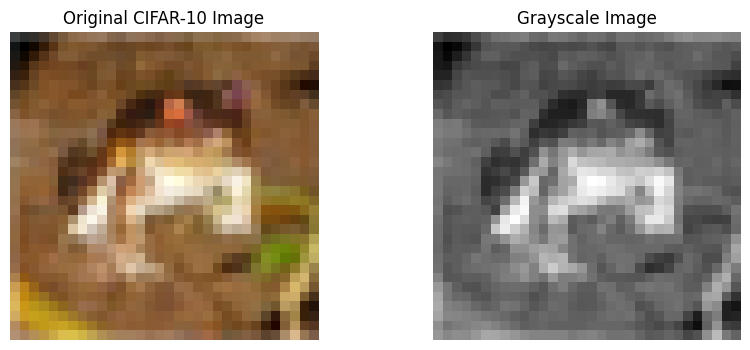

In [ ]:
plt.figure(figsize=(10, 4))

# Original RGB image
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original CIFAR-10 Image")
plt.axis("off")

# Grayscale image
plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.show()

#### Task 9: Display the original image and grayscale version

In [ ]:
# Define a 3x3 edge detection kernel
kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

print("Kernel:")
print(kernel)

Kernel:
[[-1 -1 -1]
 [-1  8 -1]
 [-1 -1 -1]]


#### Task 10: Define a 3x3 edge detection kernel

In [ ]:
# Get image dimensions
image_height, image_width = gray_image.shape

# Kernel size
kernel_size = 3

# Output size for VALID convolution
output_height = image_height - kernel_size + 1
output_width = image_width - kernel_size + 1

# Create empty output feature map
feature_map = np.zeros((output_height, output_width))

# Manual convolution
for i in range(output_height):
    for j in range(output_width):

        # Extract 3x3 region
        region = gray_image[
            i:i + kernel_size,
            j:j + kernel_size
        ]

        # Element-wise multiplication and sum
        feature_map[i, j] = np.sum(region * kernel)

print("Original grayscale shape:", gray_image.shape)
print("Feature map shape:", feature_map.shape)

Original grayscale shape: (32, 32)
Feature map shape: (30, 30)


#### Task 11: Get image dimensions

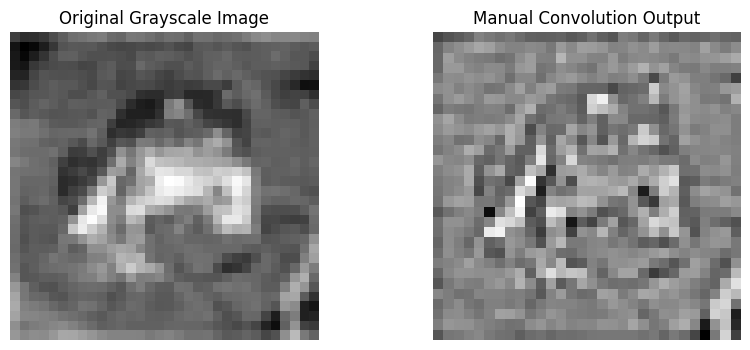

In [ ]:
plt.figure(figsize=(10, 4))

# Original grayscale image
plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

# Convolved feature map
plt.subplot(1, 2, 2)
plt.imshow(feature_map, cmap="gray")
plt.title("Manual Convolution Output")
plt.axis("off")

plt.show()

#### Task 12: Visualize the manual convolution result

## Manual Convolution Explanation

Convolution works by sliding a small kernel over the image.

At every position, the values in the image region are multiplied element-by-element with the kernel values and then added together. This produces one value in the output feature map.

The kernel moves one pixel at a time because the stride is 1.

For a 32×32 image and a 3×3 kernel with VALID padding:

Output size = 32 - 3 + 1 = 30

Therefore, the resulting feature map has a size of 30×30.

The edge-detection kernel responds strongly to changes in intensity, allowing it to highlight edges and boundaries in the image.

In [ ]:
from tensorflow.keras import layers

# Create a Conv2D layer with VALID padding
conv_valid = layers.Conv2D(
    filters=1,
    kernel_size=(3, 3),
    strides=1,
    padding="valid",
    input_shape=(32, 32, 3)
)

# Pass one image through the layer
valid_output = conv_valid(
    np.expand_dims(X_train[0], axis=0)
)

print("VALID output shape:", valid_output.shape)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


VALID output shape: (1, 30, 30, 1)


#### Task 13: Import the required library

In [ ]:
# Create a Conv2D layer with SAME padding
conv_same = layers.Conv2D(
    filters=1,
    kernel_size=(3, 3),
    strides=1,
    padding="same",
    input_shape=(32, 32, 3)
)

# Pass the same image through the layer
same_output = conv_same(
    np.expand_dims(X_train[0], axis=0)
)

print("SAME output shape:", same_output.shape)

SAME output shape: (1, 32, 32, 1)


#### Task 14: Create a Conv2D layer with SAME padding

In [ ]:
print("Input shape :", X_train[0].shape)
print("VALID output:", valid_output.shape)
print("SAME output :", same_output.shape)

Input shape : (32, 32, 3)
VALID output: (1, 30, 30, 1)
SAME output : (1, 32, 32, 1)


#### Task 15: Compare convolution output shapes

In [ ]:
# Add zero padding manually
padded_image = np.pad(
    X_train[0],
    ((1, 1), (1, 1), (0, 0)),
    mode="constant",
    constant_values=0
)

print("Original image shape :", X_train[0].shape)
print("Padded image shape   :", padded_image.shape)

Original image shape : (32, 32, 3)
Padded image shape   : (34, 34, 3)


#### Task 16: Add zero padding manually

## VALID vs SAME Padding

### VALID Padding

VALID padding does not add any pixels around the image.

For a 32×32 input and a 3×3 filter with stride 1:

Output size = 32 - 3 + 1 = 30

Therefore, the output size is 30×30.

### SAME Padding

SAME padding adds zero-padding around the image so that the spatial dimensions are preserved when stride = 1.

For a 32×32 input and a 3×3 filter with stride 1:

Output size = 32×32

SAME padding is commonly used in CNN architectures because it allows multiple convolution layers to be stacked without quickly reducing the spatial dimensions.

In [ ]:
# Conv2D with stride = 1
conv_stride1 = layers.Conv2D(
    filters=1,
    kernel_size=(3, 3),
    strides=1,
    padding="valid",
    input_shape=(32, 32, 3)
)

output_stride1 = conv_stride1(
    np.expand_dims(X_train[0], axis=0)
)

print("Stride = 1 output shape:", output_stride1.shape)

Stride = 1 output shape: (1, 30, 30, 1)


#### Task 17: Conv2D with stride = 1

In [ ]:
# Conv2D with stride = 2
conv_stride2 = layers.Conv2D(
    filters=1,
    kernel_size=(3, 3),
    strides=2,
    padding="valid",
    input_shape=(32, 32, 3)
)

output_stride2 = conv_stride2(
    np.expand_dims(X_train[0], axis=0)
)

print("Stride = 2 output shape:", output_stride2.shape)

Stride = 2 output shape: (1, 15, 15, 1)


#### Task 18: Conv2D with stride = 2

In [ ]:
print("Input shape:", X_train[0].shape)

print("\nStride = 1")
print("Output shape:", output_stride1.shape)

print("\nStride = 2")
print("Output shape:", output_stride2.shape)

Input shape: (32, 32, 3)

Stride = 1
Output shape: (1, 30, 30, 1)

Stride = 2
Output shape: (1, 15, 15, 1)


#### Task 19: Compare output shapes for different strides

## Effect of Stride

Stride determines how many pixels the convolution filter moves at each step.

### Stride = 1

The filter moves one pixel at a time. Therefore, the output retains more spatial information.

### Stride = 2

The filter moves two pixels at a time. This reduces the spatial dimensions of the output.

For a 32×32 input with a 3×3 filter and VALID padding:

Stride 1 → 30×30

Stride 2 → 15×15

Therefore, stride 2 performs spatial downsampling. It can reduce computation and sometimes be used as an alternative to pooling.

In [ ]:
# Create a Conv2D layer with 16 filters
model_vis = keras.Sequential([
    keras.layers.Conv2D(
        filters=16,
        kernel_size=(3, 3),
        activation="relu",
        padding="same",
        input_shape=(32, 32, 3)
    )
])

# Display model summary
model_vis.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 16)     │           448 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 448 (1.75 KB)

 Trainable params: 448 (1.75 KB)

 Non-trainable params: 0 (0.00 B)

#### Task 20: Create a Conv2D layer with 16 filters

In [ ]:
# Select one image
sample_image = X_train[0]

# Add batch dimension
sample_input = np.expand_dims(sample_image, axis=0)

# Generate feature maps
feature_maps = model_vis.predict(sample_input, verbose=0)

print("Feature maps shape:", feature_maps.shape)

Feature maps shape: (1, 32, 32, 16)


#### Task 21: Select one image

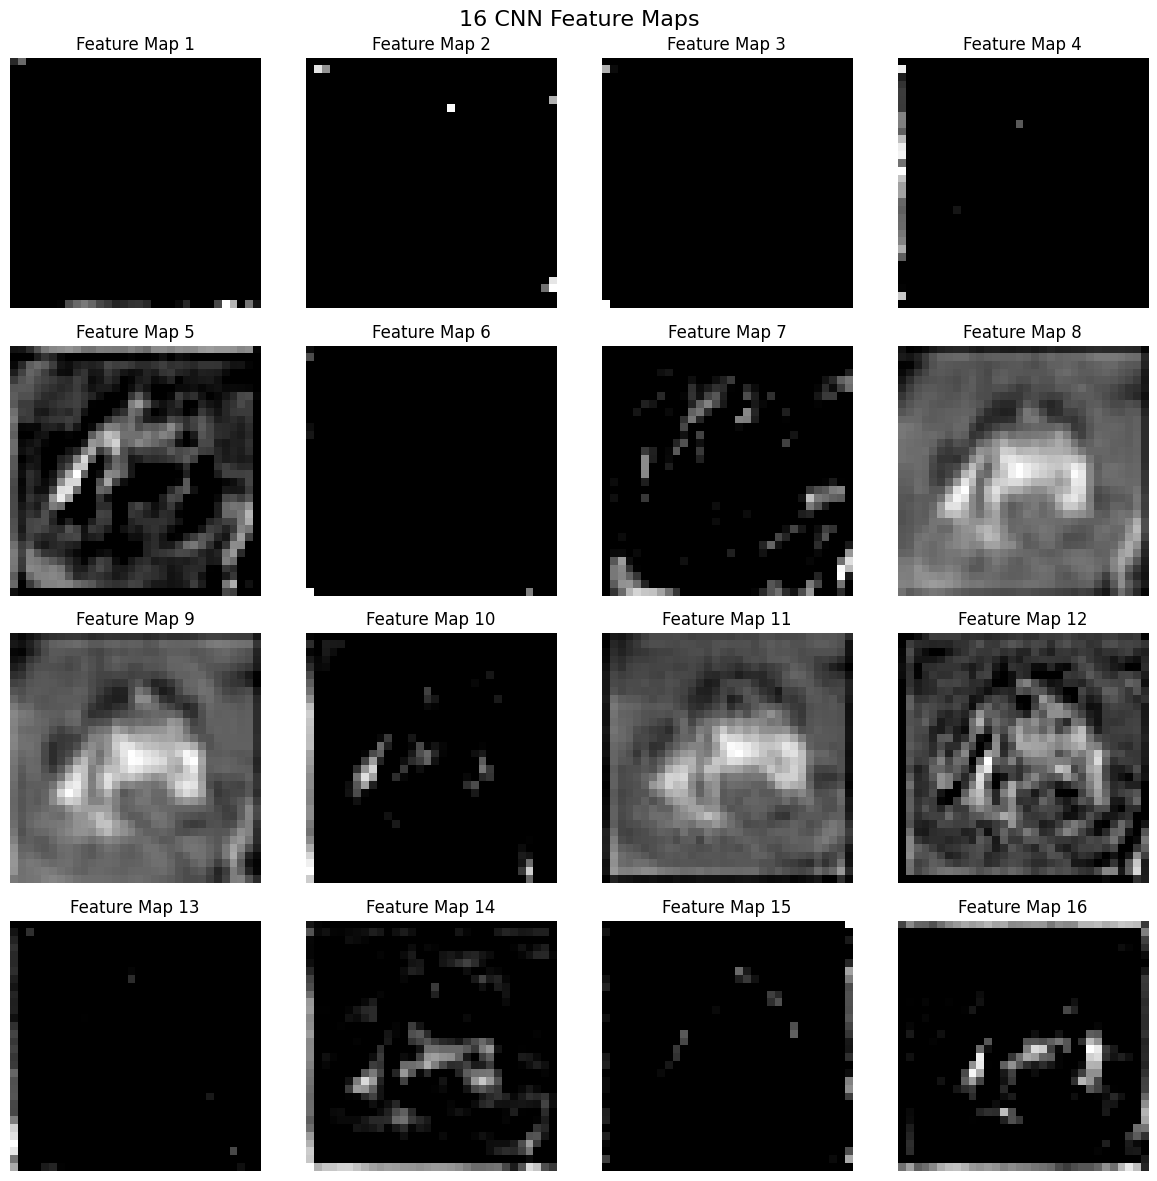

In [ ]:
# Create 4x4 grid
fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for i in range(16):
    row = i // 4
    col = i % 4

    axes[row, col].imshow(feature_maps[0, :, :, i], cmap="gray")
    axes[row, col].set_title(f"Feature Map {i + 1}")
    axes[row, col].axis("off")

plt.suptitle("16 CNN Feature Maps", fontsize=16)
plt.tight_layout()
plt.show()

#### Task 22: Create 4x4 grid

## Feature Maps

A convolutional layer contains multiple learnable filters. Each filter scans the input image and produces one feature map.

In this experiment, the Conv2D layer contains 16 filters, so it produces 16 feature maps.

The filters are initially randomly initialized. During training, the CNN learns useful filters that can detect patterns such as:

- Edges
- Gradients
- Colours
- Textures
- Shapes
- Object parts

Early CNN layers generally learn simple features such as edges and colours, while deeper layers can learn more complex patterns and object parts.

Each feature map represents the response of one learned filter across the image.

# Practical 3: Pooling Layers and CNN Architectures

In [ ]:
# Add MaxPooling after A2 model
max_model = keras.Sequential([
    model_vis,
    keras.layers.MaxPooling2D((2, 2))
])

max_maps = max_model.predict(X_train[:1], verbose=0)

print("Before Pooling:", feature_maps.shape)
print("After MaxPooling:", max_maps.shape)

Before Pooling: (1, 32, 32, 16)
After MaxPooling: (1, 16, 16, 16)


#### Task 23: Add MaxPooling after A2 model

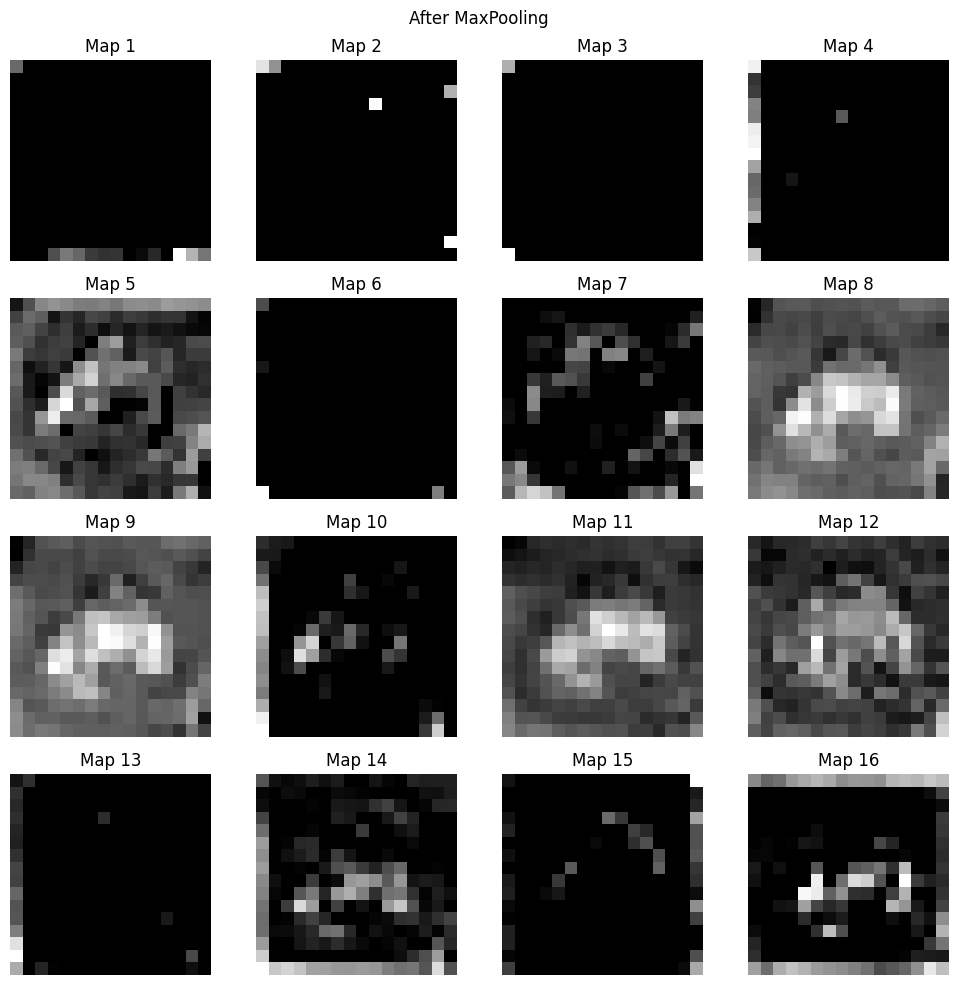

In [ ]:
fig, ax = plt.subplots(4, 4, figsize=(10, 10))

for i in range(16):
    ax[i//4, i%4].imshow(max_maps[0, :, :, i], cmap="gray")
    ax[i//4, i%4].axis("off")
    ax[i//4, i%4].set_title(f"Map {i+1}")

plt.suptitle("After MaxPooling")
plt.tight_layout()
plt.show()

#### Task 24: Visualize feature maps after max pooling

In [ ]:
avg_model = keras.Sequential([
    model_vis,
    keras.layers.AveragePooling2D((2, 2))
])

avg_maps = avg_model.predict(X_train[:1], verbose=0)

print("Before Pooling:", feature_maps.shape)
print("After AveragePooling:", avg_maps.shape)

Before Pooling: (1, 32, 32, 16)
After AveragePooling: (1, 16, 16, 16)


#### Task 25: Apply average pooling and check the output shape

## MaxPooling vs AveragePooling

MaxPooling selects the maximum value from each 2×2 region, so it preserves the strongest activation of a feature.

AveragePooling calculates the mean value of the region, producing a smoother feature map.

MaxPooling is commonly preferred because it preserves strong features and provides useful spatial downsampling.

GlobalAveragePooling2D can also replace Flatten in modern CNNs by reducing each feature map to a single average value.

In [ ]:
flatten_model = keras.Sequential([
    model_vis,
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten()
])

flat = flatten_model.predict(X_train[:1], verbose=0)

print("Before Flatten:", max_maps.shape)
print("After Flatten :", flat.shape)

Before Flatten: (1, 16, 16, 16)
After Flatten : (1, 4096)


#### Task 26: Flatten the pooled feature maps

## Flatten Layer

Flatten converts the 3D feature maps (H, W, C) into a 1D vector before the Dense layers.

Here:

16 × 16 × 16 = 4096

So the Flatten layer produces 4096 values.

A large flattened representation can increase the number of parameters in the following Dense layer, which is why modern CNNs often use GlobalAveragePooling2D.

In [ ]:
lenet5 = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(6, 5, activation="tanh"),
    keras.layers.AveragePooling2D(2, 2),
    keras.layers.Conv2D(16, 5, activation="tanh"),
    keras.layers.AveragePooling2D(2, 2),
    keras.layers.Flatten(),
    keras.layers.Dense(120, activation="tanh"),
    keras.layers.Dense(84, activation="tanh"),
    keras.layers.Dense(10, activation="softmax")
])

lenet5.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

#### Task 27: lenet5 = keras.Sequential([

## LeNet-5 Architecture

LeNet-5 was introduced by Yann LeCun and colleagues and is one of the early successful CNN architectures.

Its basic pattern is:

Conv → Pool → Conv → Pool → Flatten → Dense → Dense

LeNet-5 originally used tanh activation, AveragePooling and 5×5 convolution filters.

Modern CNNs generally use ReLU, MaxPooling and smaller 3×3 filters, but LeNet-5 is important historically because it established the basic convolution-pooling-Dense architecture used by many later CNNs.

In [ ]:
cnn = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),

    keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
    keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
    keras.layers.MaxPooling2D(2),

    keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
    keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
    keras.layers.MaxPooling2D(2),

    keras.layers.Conv2D(128, 3, activation="relu", padding="same"),
    keras.layers.GlobalAveragePooling2D(),

    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

cnn.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

#### Task 28: cnn = keras.Sequential([

In [ ]:
print("Total parameters:", cnn.count_params())

Total parameters: 175018


#### Task 29: Count the CNN model parameters

## Why Stack Two Convolution Layers Before Pooling?

The first convolution layer can learn simple features such as edges, colours and gradients.

The second convolution layer can combine these simple features into slightly more complex patterns.

After two convolution layers, pooling reduces the spatial dimensions.

Therefore, stacking convolution layers before pooling allows the network to learn richer feature representations before reducing the image resolution.

# Practical 4: CNN Training and Backpropagation

# A4.1 Backpropagation in CNN

### Forward Pass

The input image passes through the CNN in the following order:

Input Image → Convolution → ReLU → Pooling → Convolution → ReLU → Pooling → Flatten/GAP → Dense → Softmax → Loss

The network produces class probabilities and compares them with the true labels using categorical cross-entropy loss.

### Backward Pass

Backpropagation calculates how much each weight contributed to the error and updates the weights using gradients.

For Dense layers, the gradient flows backward through the weights and activation functions.

For convolution layers, the gradient is propagated back through the convolution operation so that each kernel weight can be updated.

### Gradient Through MaxPooling

In MaxPooling, only the maximum value from each pooling window receives the gradient. The other positions receive zero gradient. This is sometimes called the "winner takes all" behaviour.

### Gradient Through AveragePooling

In AveragePooling, the incoming gradient is distributed across all values in the pooling window because the output is calculated as their average.

### Gradient Through Flatten

Flatten only reshapes the feature maps into a vector. Therefore, the gradient is simply reshaped back to the original feature-map dimensions.

The optimizer then uses these gradients to update the learnable parameters and reduce the loss.

In [ ]:
# Use CNN created in A3
model_cnn = cnn

model_cnn.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

#### Task 30: Use CNN created in A3

In [ ]:
model_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

#### Task 31: Compile the CNN model

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

#### Task 32: Set up early stopping and learning-rate reduction

In [ ]:
history = model_cnn.fit(
    X_train,
    y_train_oh,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 20ms/step - accuracy: 0.3296 - loss: 1.7662 - val_accuracy: 0.4338 - val_loss: 1.5458 - learning_rate: 0.0010
Epoch 2/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5090 - loss: 1.3410 - val_accuracy: 0.5616 - val_loss: 1.2276 - learning_rate: 0.0010
Epoch 3/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5920 - loss: 1.1338 - val_accuracy: 0.6206 - val_loss: 1.0615 - learning_rate: 0.0010
Epoch 4/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6486 - loss: 0.9846 - val_accuracy: 0.6522 - val_loss: 0.9959 - learning_rate: 0.0010
Epoch 5/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.6849 - loss: 0.8851 - val_accuracy: 0.6722 - val_loss: 0.9243 - learning_rate: 0.0010
Epoch 6/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7180 - loss: 0.7965 - val_accuracy: 0.7088 - val_loss: 0.8433 - learning_rate: 0.0010
Epoch 7/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7471 - loss: 0.7209 

#### Task 33: Train the CNN model

### ReduceLROnPlateau

ReduceLROnPlateau reduces the learning rate when validation loss stops improving.

Here, the learning rate is multiplied by 0.5 after 5 epochs without improvement.

This allows the model to make larger updates during early training and smaller updates when fine-tuning near a good solution.

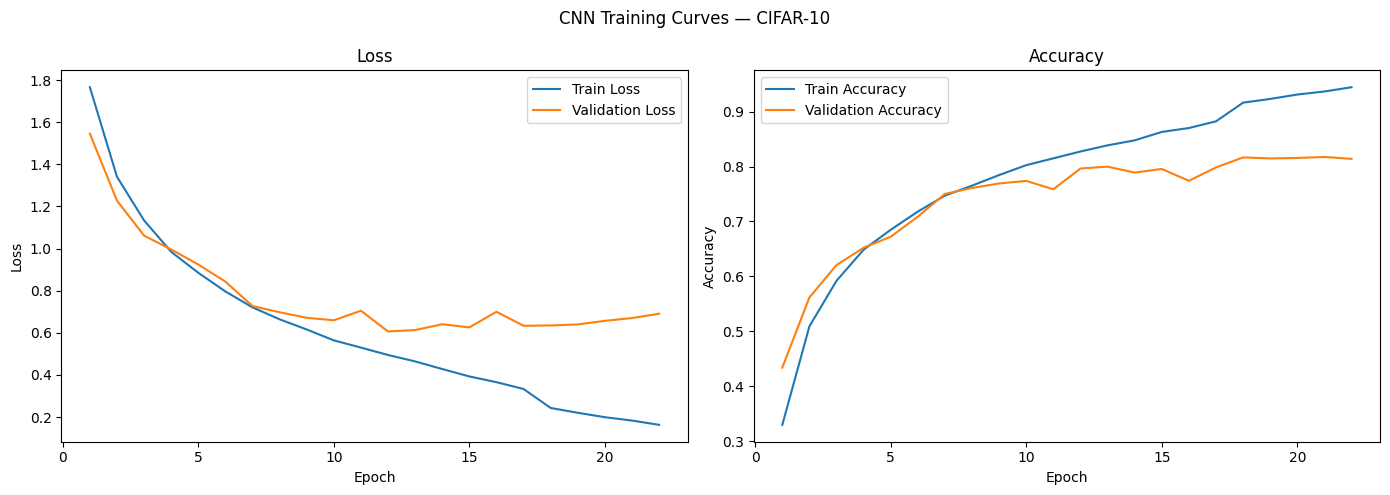

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(history.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Loss
ax[0].plot(epochs, history.history["loss"], label="Train Loss")
ax[0].plot(epochs, history.history["val_loss"], label="Validation Loss")
ax[0].set_title("Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()

# Accuracy
ax[1].plot(epochs, history.history["accuracy"], label="Train Accuracy")
ax[1].plot(epochs, history.history["val_accuracy"], label="Validation Accuracy")
ax[1].set_title("Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()

plt.suptitle("CNN Training Curves — CIFAR-10")
plt.tight_layout()
plt.show()

#### Task 34: Plot training and validation curves

In [ ]:
print("Final Train Accuracy:",
      history.history["accuracy"][-1])

print("Final Validation Accuracy:",
      history.history["val_accuracy"][-1])

print("Final Train Loss:",
      history.history["loss"][-1])

print("Final Validation Loss:",
      history.history["val_loss"][-1])

Final Train Accuracy: 0.9444444179534912
Final Validation Accuracy: 0.8140000104904175
Final Train Loss: 0.16322389245033264
Final Validation Loss: 0.690727174282074


#### Task 35: Print the final training results

In [ ]:
class LRLogger(ReduceLROnPlateau):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.lr_epochs = []

    def on_epoch_end(self, epoch, logs=None):
        old_lr = float(tf.keras.backend.get_value(self.model.optimizer.learning_rate))
        super().on_epoch_end(epoch, logs)
        new_lr = float(tf.keras.backend.get_value(self.model.optimizer.learning_rate))

        if new_lr < old_lr:
            self.lr_epochs.append(epoch + 1)


lr_logger = LRLogger(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

#### Task 36: Track when the learning rate is reduced

In [ ]:
history = model_cnn.fit(
    X_train,
    y_train_oh,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop, lr_logger],
    verbose=1
)

Epoch 1/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8701 - loss: 0.3775 - val_accuracy: 0.8136 - val_loss: 0.5636 - learning_rate: 2.5000e-04
Epoch 2/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8767 - loss: 0.3527 - val_accuracy: 0.8120 - val_loss: 0.5824 - learning_rate: 2.5000e-04
Epoch 3/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8824 - loss: 0.3395 - val_accuracy: 0.8162 - val_loss: 0.5672 - learning_rate: 2.5000e-04
Epoch 4/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8888 - loss: 0.3239 - val_accuracy: 0.8124 - val_loss: 0.5769 - learning_rate: 2.5000e-04
Epoch 5/50
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8919 - loss: 0.3113 - val_accuracy: 0.8166 - val_loss: 0.5661 - learning_rate: 2.5000e-04
Epoch 6/50
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8990 - loss: 0.2922
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.896

#### Task 37: Train again while logging learning-rate changes

# Practical 5: Data Augmentation

## Why Data Augmentation?

Data augmentation creates modified versions of training images using random transformations such as flipping, rotation and zooming. It increases data variety without collecting new images and helps reduce overfitting. Training accuracy may decrease slightly, but validation and test performance may improve.

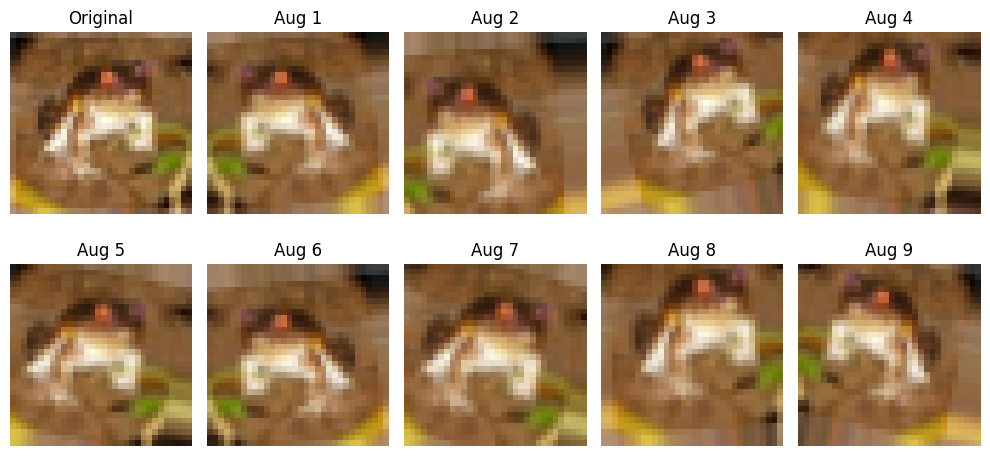

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode="nearest"
)

img = X_train[0]
aug = datagen.flow(np.array([img]), batch_size=1)

plt.figure(figsize=(10,5))
plt.subplot(2,5,1)
plt.imshow(img)
plt.title("Original")
plt.axis("off")

for i in range(9):
    plt.subplot(2,5,i+2)
    plt.imshow(next(aug)[0])
    plt.title(f"Aug {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

#### Task 38: Import the required library

In [ ]:
model_aug = keras.models.clone_model(cnn)
model_aug.compile(optimizer="adam",
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3)
]

history_aug = model_aug.fit(
    datagen.flow(X_train, y_train_oh, batch_size=64),
    epochs=30,
    validation_data=(X_test, y_test_oh),
    callbacks=callbacks
)

Epoch 1/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 46s 55ms/step - accuracy: 0.3160 - loss: 1.7888 - val_accuracy: 0.4236 - val_loss: 1.5228 - learning_rate: 0.0010
Epoch 2/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 34s 44ms/step - accuracy: 0.4649 - loss: 1.4479 - val_accuracy: 0.5133 - val_loss: 1.3225 - learning_rate: 0.0010
Epoch 3/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 36s 45ms/step - accuracy: 0.5362 - loss: 1.2795 - val_accuracy: 0.5642 - val_loss: 1.2398 - learning_rate: 0.0010
Epoch 4/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 34s 43ms/step - accuracy: 0.5807 - loss: 1.1649 - val_accuracy: 0.5924 - val_loss: 1.1765 - learning_rate: 0.0010
Epoch 5/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 35s 44ms/step - accuracy: 0.6165 - loss: 1.0772 - val_accuracy: 0.6245 - val_loss: 1.0769 - learning_rate: 0.0010
Epoch 6/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 34s 43ms/step - accuracy: 0.6426 - loss: 1.0133 - val_accuracy: 0.6199 - val_loss: 1.1394 - learning_rate: 0.0010
Epoch 7/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 33s 42ms/step - accuracy: 0.6600 - l

#### Task 39: model_aug = keras.models.clone_model(cnn)

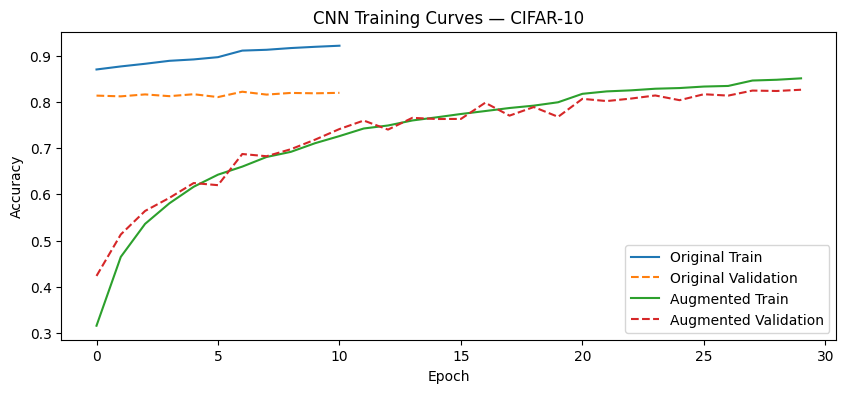

In [ ]:
plt.figure(figsize=(10,4))

for h, name in [(history, "Original"), (history_aug, "Augmented")]:
    plt.plot(h.history["accuracy"], label=name+" Train")
    plt.plot(h.history["val_accuracy"], "--", label=name+" Validation")

plt.title("CNN Training Curves — CIFAR-10")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

#### Task 40: Compare original and augmented training curves

In [ ]:
augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomTranslation(0.1, 0.1)
])

model_modern = keras.Sequential([
    keras.layers.Input(shape=(32,32,3)),
    augmentation,
    *cnn.layers
])

model_modern.compile(optimizer="adam",
                     loss="categorical_crossentropy",
                     metrics=["accuracy"])

history_modern = model_modern.fit(
    X_train, y_train_oh,
    epochs=30, batch_size=64,
    validation_data=(X_test, y_test_oh),
    callbacks=callbacks
)

Epoch 1/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.6685 - loss: 0.9484 - val_accuracy: 0.6804 - val_loss: 0.9795 - learning_rate: 0.0010
Epoch 2/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.6861 - loss: 0.8880 - val_accuracy: 0.7204 - val_loss: 0.8421 - learning_rate: 0.0010
Epoch 3/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.7002 - loss: 0.8580 - val_accuracy: 0.6885 - val_loss: 1.0019 - learning_rate: 0.0010
Epoch 4/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.7258 - loss: 0.7812 - val_accuracy: 0.7266 - val_loss: 0.8623 - learning_rate: 5.0000e-04
Epoch 5/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.7332 - loss: 0.7568 - val_accuracy: 0.7266 - val_loss: 0.8350 - learning_rate: 5.0000e-04


#### Task 41: augmentation = keras.Sequential([

In [ ]:
for name, model in [
    ("Original CNN", cnn),
    ("ImageDataGenerator CNN", model_aug),
    ("Modern Augmentation CNN", model_modern)
]:
    loss, acc = model.evaluate(X_test, y_test_oh, verbose=0)
    print(f"{name}: {acc*100:.2f}%")

Original CNN: 68.04%
ImageDataGenerator CNN: 82.63%
Modern Augmentation CNN: 68.04%


#### Task 42: Evaluate the augmentation models

# Practical 6: Transfer Learning

## Why Transfer Learning?

Transfer learning uses a model pretrained on a large dataset such as ImageNet. Feature extraction freezes the pretrained layers and trains a new classification head. Fine-tuning unfreezes some pretrained layers and trains them with a low learning rate. It saves time and can improve accuracy when training data is limited.

In [ ]:
import tensorflow as tf
from tensorflow import keras

X_train_r = tf.image.resize(X_train, (96, 96))
X_test_r = tf.image.resize(X_test, (96, 96))

base_model = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=(96, 96, 3))
x = keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)
x = base_model(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
outputs = keras.layers.Dense(10, activation="softmax")(x)

model_tl = keras.Model(inputs, outputs)
model_tl.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

#### Task 43: Import the required library

In [ ]:
model_tl.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_fe = model_tl.fit(
    X_train_r, y_train_oh,
    epochs=20, batch_size=64,
    validation_split=0.1
)

_, acc_fe = model_tl.evaluate(X_test_r, y_test_oh, verbose=0)
print(f"Feature Extraction Accuracy: {acc_fe*100:.2f}%")

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 31ms/step - accuracy: 0.8052 - loss: 0.5743 - val_accuracy: 0.8536 - val_loss: 0.4181
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.8645 - loss: 0.3949 - val_accuracy: 0.8508 - val_loss: 0.4215
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.8758 - loss: 0.3595 - val_accuracy: 0.8640 - val_loss: 0.3855
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.8817 - loss: 0.3381 - val_accuracy: 0.8698 - val_loss: 0.3902
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.8898 - loss: 0.3221 - val_accuracy: 0.8642 - val_loss: 0.3949
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.8927 - loss: 0.3082 - val_accuracy: 0.8524 - val_loss: 0.4079
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.8943 - loss: 0.3015 - val_accuracy: 0.8616 - val_loss: 0.3919
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.8971 - loss: 0.2937 - 

#### Task 44: model_tl.compile(

In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

model_tl.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_ft = model_tl.fit(
    X_train_r, y_train_oh,
    epochs=10, batch_size=32,
    validation_split=0.1
)

_, acc_ft = model_tl.evaluate(X_test_r, y_test_oh, verbose=0)
print(f"Fine-Tuning Accuracy: {acc_ft*100:.2f}%")

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 41s 21ms/step - accuracy: 0.9141 - loss: 0.2419 - val_accuracy: 0.8658 - val_loss: 0.4271
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 24s 14ms/step - accuracy: 0.9453 - loss: 0.1635 - val_accuracy: 0.8702 - val_loss: 0.4153
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.9647 - loss: 0.1132 - val_accuracy: 0.8738 - val_loss: 0.4171
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.9791 - loss: 0.0760 - val_accuracy: 0.8782 - val_loss: 0.4199
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.9875 - loss: 0.0525 - val_accuracy: 0.8802 - val_loss: 0.4284
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.9934 - loss: 0.0348 - val_accuracy: 0.8862 - val_loss: 0.4311
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.9972 - loss: 0.0235 - val_accuracy: 0.8874 - val_loss: 0.4228
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.9979 -

#### Task 45: base_model.trainable = True

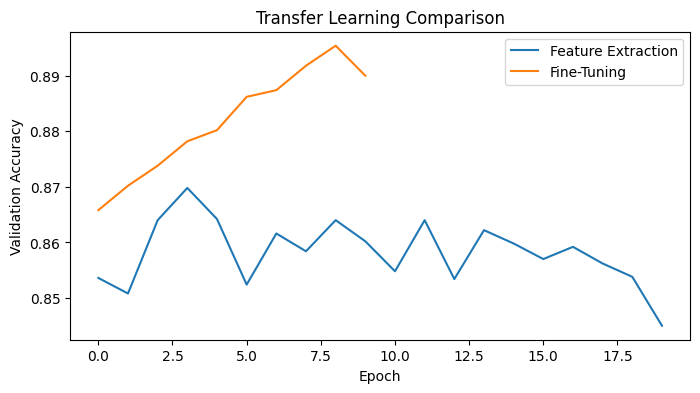

In [ ]:
plt.figure(figsize=(8,4))

plt.plot(history_fe.history["val_accuracy"], label="Feature Extraction")
plt.plot(history_ft.history["val_accuracy"], label="Fine-Tuning")

plt.title("Transfer Learning Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()

#### Task 46: Compare transfer-learning validation accuracy

## Residual Connection

A residual connection adds the input shortcut to the output of convolution layers. It helps gradients flow through deeper networks and reduces the vanishing-gradient problem. This idea is used in ResNet architectures.